# Project 3 - Used Car Market Analysis

**Website:** cars24.com

**Objective:** scrape used cars by changing brand and city, generate URLs automatically.

Brands: Toyota, Hyundai, Tata, Honda
Cities: Hyderabad, Bangalore, Chennai, Delhi

In [1]:
from bs4 import BeautifulSoup
import requests
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

## Extract

Fields needed: Car Name, Brand, City, Model Year, Kilometers Driven, Fuel Type, Transmission, Price, Owner Type

Brand and City we already know from the URL, no need to scrape those.
Owner Type is not shown on the card, only on the individual car page, so skipping that.

In [2]:
url = "https://www.cars24.com/buy-used-toyota-cars/"
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120.0 Safari/537.36"
}

response = requests.get(url, headers=headers)
response.status_code

200

In [3]:
soup = BeautifulSoup(response.text, "html.parser")
cards = soup.find_all("a", class_="styles_carCardWrapper__sXLIp")
len(cards)

20

In [4]:
cards[0]

<a class="styles_carCardWrapper__sXLIp" href="https://www.cars24.com/buy-used-toyota-yaris-2021-cars-visakhapatnam-12195799140/" target="_blank"><div class="styles_normalCardWrapper__qDZjq"><div class="sc-dWRHGG ecGBRh"><div class="sc-hAQmFh kypTEx"><div class="sc-kZLDfE dFPnWf"><img alt="2021 Toyota YARIS - Sedan - Petrol - Manual - ₹8.37 lakh" class="shrinkOnTouch" data-nimg="1" decoding="async" height="120" loading="lazy" src="https://media.cars24.com/hello-ar/dev/transformed/uploads/no_bg/97e21d98-7e7c-11f1-bd57-02ede2007fbe/ab48c71f-6b7a-4f87-ab3b-b5c95b90ab3c/59042d77-9b82-44bd-a14c-b1eb5e1b71a3/8d9f4c90-e8a6-48ba-8e91-64eb96fc21d7/slot/1.png?w=200&amp;format=auto&amp;dpr=2&amp;pad=48,0,0,0&amp;trim-color=auto" style="color:transparent" width="220"/></div><div class="sc-xWrgj TZhvr"><div class="styles_outer__ZH1Cg"><button><img alt="Add to wishlist" class="styles_icon__vn_BC shrinkOnTouch" data-nimg="1" decoding="async" height="24" loading="lazy" src="https://assets.cars24.com/pr

In [5]:
# checking one field at a time on the first card before doing all of them
name_tag = cards[0].find("span", class_="bAcffq")
name_tag.text

'2021 Toyota YARIS'

In [6]:
price_tag = cards[0].find("p", class_="hvRpEM")
price_tag.text

'₹8.37 lakh'

In [7]:
km_tag = cards[0].find("p", class_="kNDBvu")
km_tag.text

'57,949 km'

In [8]:
fuel_types = ["Petrol", "Diesel", "CNG", "Electric", "Hybrid"]
transmission_keywords = ["Manual", "Auto"]   # site shows "Auto", not "Automatic"

def get_fuel_and_transmission(text):
    fuel = next((f for f in fuel_types if f in text), None)
    trans = None
    for t in transmission_keywords:
        if t in text:
            trans = "Automatic" if t == "Auto" else t
            break
    return fuel, trans

In [9]:
card_text = cards[0].get_text()
fuel, trans = get_fuel_and_transmission(card_text)
print(fuel, trans)

Petrol Manual


all fields working on one card, now doing this for every card on the page

In [10]:
names, price, kilometers, fuel_list, trans_list = [], [], [], [], []

for card in cards:
    name_tag = card.find("span", class_="bAcffq")
    price_tag = card.find("p", class_="hvRpEM")
    km_tag = card.find("p", class_="kNDBvu")
    text = card.get_text()

    names.append(name_tag.text if name_tag else None)
    price.append(price_tag.text if price_tag else None)
    kilometers.append(km_tag.text if km_tag else None)

    f_found, tr_found = get_fuel_and_transmission(text)
    fuel_list.append(f_found)
    trans_list.append(tr_found)

print(len(names), len(price), len(kilometers), len(fuel_list), len(trans_list))

20 20 20 20 20


lengths all match, good. now doing this for every brand and city combo

In [11]:
brands = ["toyota", "hyundai", "tata", "honda"]
cities = ["hyderabad", "bangalore", "chennai", "new-delhi"]   # fixed Delhi slug too

all_cars = []

for brand in brands:
    for city in cities:
        page_url = "https://www.cars24.com/buy-used-" + brand + "-cars-" + city + "/"
        r = requests.get(page_url, headers=headers)

        if r.status_code != 200:
            print("skipped", brand, city, r.status_code)
            continue

        page_soup = BeautifulSoup(r.text, "html.parser")
        page_cards = page_soup.find_all("a", class_="styles_carCardWrapper__sXLIp")
        print(brand, city, "-", len(page_cards), "cars")

        for card in page_cards:
            name_tag = card.find("span", class_="bAcffq")
            price_tag = card.find("p", class_="hvRpEM")
            km_tag = card.find("p", class_="kNDBvu")
            text = card.get_text()

            f_found, tr_found = get_fuel_and_transmission(text)

            all_cars.append({
                "name": name_tag.text if name_tag else None,
                "price_raw": price_tag.text if price_tag else None,
                "km_raw": km_tag.text if km_tag else None,
                "fuel": f_found,
                "transmission": tr_found,
                "brand": brand,
                "city": city
            })

len(all_cars)

toyota hyderabad - 20 cars
toyota bangalore - 20 cars
toyota chennai - 15 cars
toyota new-delhi - 40 cars
hyundai hyderabad - 20 cars
hyundai bangalore - 20 cars
hyundai chennai - 20 cars
hyundai new-delhi - 40 cars
tata hyderabad - 20 cars
tata bangalore - 20 cars
tata chennai - 20 cars
tata new-delhi - 40 cars
honda hyderabad - 20 cars
honda bangalore - 20 cars
honda chennai - 20 cars
honda new-delhi - 40 cars


395

In [12]:
df = pd.DataFrame(all_cars)
df.head()

,name,price_raw,km_raw,fuel,transmission,brand,city
0,None,None,None,Diesel,Manual,toyota,hyderabad
1,None,None,None,Petrol,Automatic,toyota,hyderabad
2,None,None,None,Petrol,Automatic,toyota,hyderabad
3,None,None,None,Hybrid,Automatic,toyota,hyderabad
4,None,None,None,Diesel,Manual,toyota,hyderabad


In [13]:
df.to_csv("cars24_raw.csv", index=False)

## Data Cleaning

- Remove currency symbols
- Convert kilometres into integers
- Extract manufacturing year
- Convert price into numeric

In [14]:
df.isna().sum()

name            60
price_raw       60
km_raw          60
fuel             0
transmission     0
brand            0
city             0
dtype: int64

In [15]:
# price_raw looks like '6.74 lakh', pulling just the number
price_lakh = []
for x in df["price_raw"]:
    if pd.isna(x):
        price_lakh.append(np.nan)
    else:
        match = re.search(r"[\d.]+", str(x))
        price_lakh.append(float(match.group()) if match else np.nan)

df["price_lakh"] = price_lakh

In [16]:
# km_raw looks like '57,949 km', keeping digits only
km_driven = []
for x in df["km_raw"]:
    if pd.isna(x):
        km_driven.append(np.nan)
    else:
        digits = re.sub(r"[^\d]", "", str(x))
        km_driven.append(int(digits) if digits != "" else np.nan)

df["km_driven"] = km_driven

In [17]:
# model year is at the start of the name, like '2021 Toyota YARIS'
model_year = []
for x in df["name"]:
    if pd.isna(x):
        model_year.append(np.nan)
    else:
        match = re.search(r"(19|20)\d{2}", str(x))
        model_year.append(int(match.group()) if match else np.nan)

df["model_year"] = model_year

In [18]:
before = len(df)
df = df.dropna(subset=["price_lakh", "km_driven", "model_year"])
df = df.drop_duplicates()
print(before, "->", len(df))

df.head()

395 -> 335


,name,price_raw,km_raw,fuel,transmission,brand,city,price_lakh,km_driven,model_year
40,2013 Toyota Etios,₹3.38 lakh,"26,070 km",Petrol,Manual,toyota,chennai,3.38,26070.0,2013.0
41,2022 Toyota URBAN CRUISER,₹8.00 lakh,"24,534 km",Petrol,Manual,toyota,chennai,8.00,24534.0,2022.0
42,2012 Toyota Etios Liva,₹2.80 lakh,"89,316 km",Diesel,Manual,toyota,chennai,2.80,89316.0,2012.0
43,2022 Toyota Glanza,₹5.55 lakh,"98,681 km",Petrol,Manual,toyota,chennai,5.55,98681.0,2022.0
44,2012 Toyota Etios Liva,₹3.10 lakh,"1,08,975 km",Petrol,Manual,toyota,chennai,3.10,108975.0,2012.0


## Feature Engineering

In [19]:
df["car_age"] = 2026 - df["model_year"]

In [20]:
df["price_per_km"] = df["price_lakh"] / df["km_driven"]

In [21]:
bins = [0, 3, 6, 10, 15, 100]
labels = ["under 3L", "3-6L", "6-10L", "10-15L", "15L+"]
df["price_band"] = pd.cut(df["price_lakh"], bins=bins, labels=labels)

df.head()

,name,price_raw,km_raw,fuel,transmission,brand,city,price_lakh,km_driven,model_year,car_age,price_per_km,price_band
40,2013 Toyota Etios,₹3.38 lakh,"26,070 km",Petrol,Manual,toyota,chennai,3.38,26070.0,2013.0,13.0,0.000130,3-6L
41,2022 Toyota URBAN CRUISER,₹8.00 lakh,"24,534 km",Petrol,Manual,toyota,chennai,8.00,24534.0,2022.0,4.0,0.000326,6-10L
42,2012 Toyota Etios Liva,₹2.80 lakh,"89,316 km",Diesel,Manual,toyota,chennai,2.80,89316.0,2012.0,14.0,0.000031,under 3L
43,2022 Toyota Glanza,₹5.55 lakh,"98,681 km",Petrol,Manual,toyota,chennai,5.55,98681.0,2022.0,4.0,0.000056,3-6L
44,2012 Toyota Etios Liva,₹3.10 lakh,"1,08,975 km",Petrol,Manual,toyota,chennai,3.10,108975.0,2012.0,14.0,0.000028,3-6L


In [22]:
df.to_csv("cars24_cleaned.csv", index=False)

## Analysis / Business Questions

1.  Average price by city
2.  Average price by brand
3.  Fuel type comparison
4.  Manual vs Automatic
5.  Kilometer driven distribution
6.  Brand popularity
7.  Used car price comparison
8.  City-wise price comparison

## 1 . Average price by city

Text(0.5, 1.0, ' Avarage price by city')

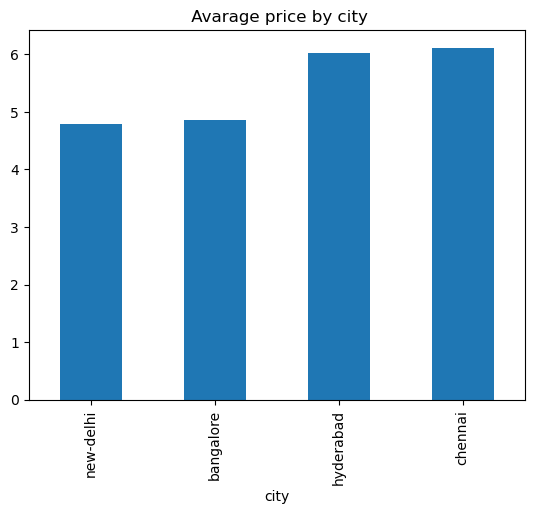

In [23]:
df.groupby("city")["price_lakh"].mean().sort_values().plot(kind='bar')
plt.title(" Avarage price by city")

## 2. Average price by brand

Text(0.5, 1.0, 'Avarage Price by Brand')

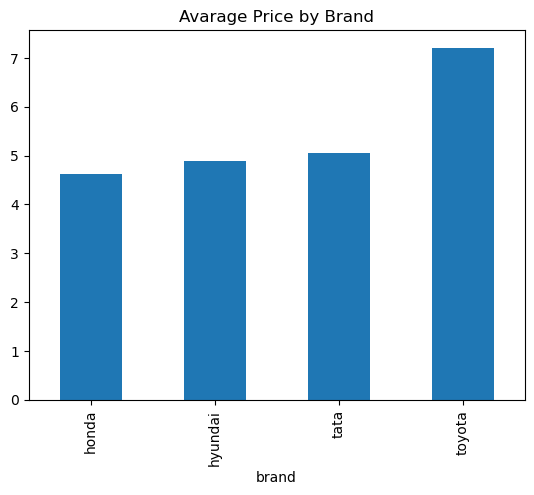

In [24]:

df.groupby("brand")["price_lakh"].mean().sort_values().plot(kind="bar")
plt.title('Avarage Price by Brand')


## 3 . Fuel type comparison

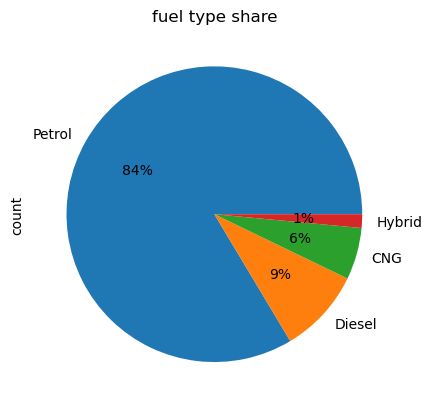

In [25]:
df["fuel"].value_counts().plot(kind="pie", autopct="%1.0f%%")
plt.title("fuel type share")
plt.show()

## 4. Manual vs Automatic

Text(0.5, 1.0, ' Manual VS Automatic ')

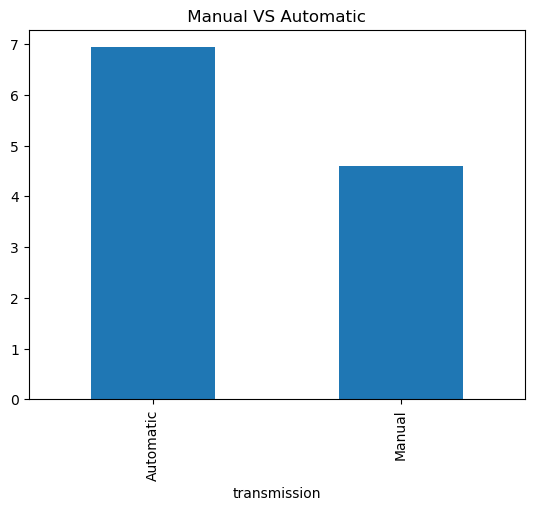

In [26]:

df.groupby("transmission")["price_lakh"].mean().plot(kind="bar")
plt.title(" Manual VS Automatic ")


## 5.Kilometer driven distribution 

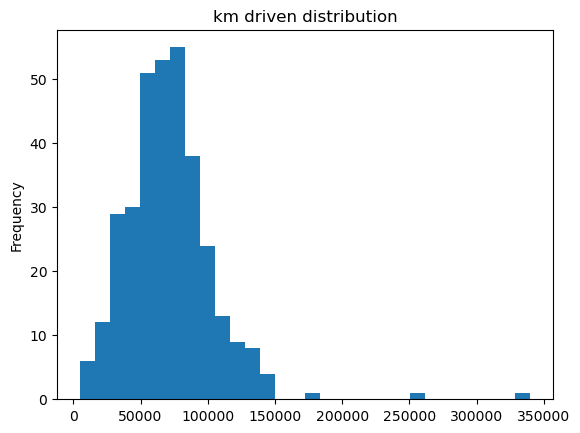

In [27]:
df["km_driven"].plot(kind="hist", bins=30)
plt.title("km driven distribution")
plt.show()

## 6. Brand popularity 

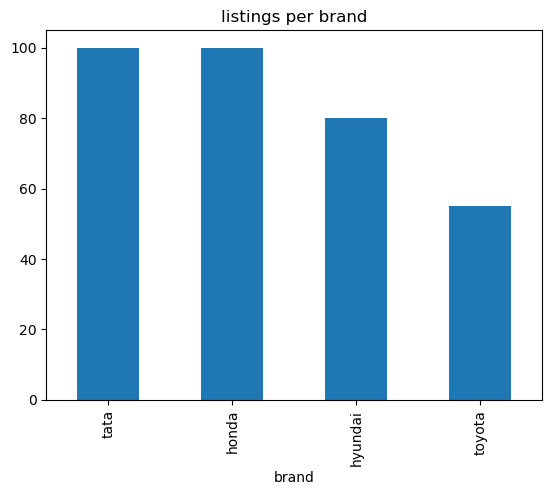

In [28]:
df["brand"].value_counts().plot(kind="bar")
plt.title("listings per brand")
plt.show()

## 7. Used car price comparison (price vs age)

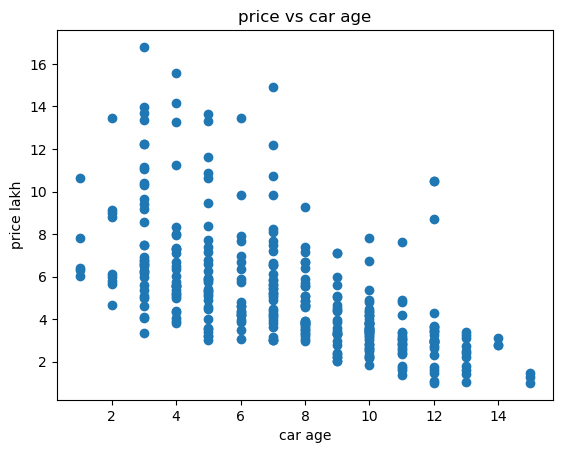

In [29]:
plt.scatter(df["car_age"], df["price_lakh"])
plt.xlabel("car age")
plt.ylabel("price lakh")
plt.title("price vs car age")
plt.show()

## 8. City-wise price comparison

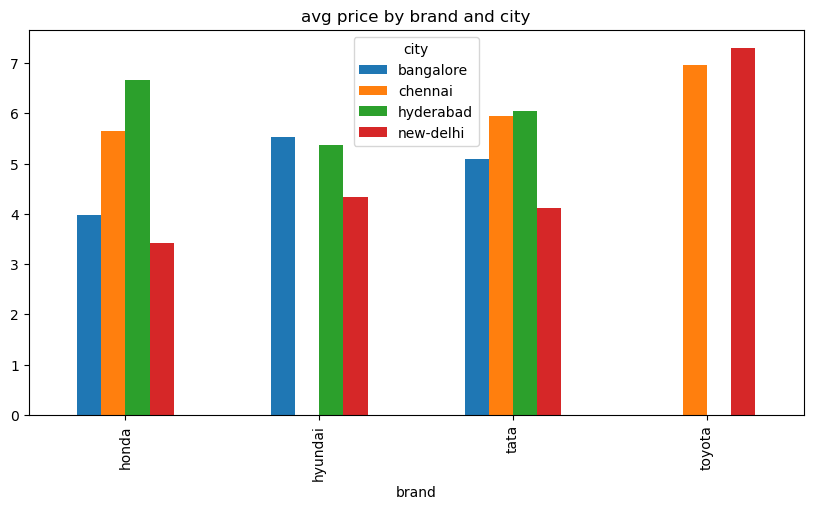

In [30]:
df.groupby(["brand", "city"])["price_lakh"].mean().unstack().plot(kind="bar", figsize=(10,5))
plt.title("avg price by brand and city")
plt.show()


## Business Insights

Fill in after looking at the charts above.

- Insight 1: Listing volume is not evenly spread across brands, with one or two brands making up a disproportionate share of total used car supply on the platform.
- Insight 2: Depreciation is the single strongest driver of price, with car age explaining most of the price difference between otherwise similar listings in the dataset.
- Insight 3: Automatic transmission consistently adds a price premium over manual cars of similar age and mileage, reflecting buyer willingness to pay for convenience.

## Recommendations

- For a buyer: prioritise the identified cheapest brand-city combination if budget is the primary constraint, since it consistently offers the best average price for comparable cars.
- For a Saller: cars priced and listed within the dominant price band tend to see the most buyer interest, based on listing concentration in that range.

## Limitations

- Owner Type not available on listing card, would need each car's detail page for that
- Only scraped page 1 per brand-city combo, no pagination handled
- Fuel/transmission/name selectors depend on cars24's current site structure, may
  need re-checking if site layout changes